# Curve local projections and controls comparison

Table 3.3 and Figure 3.2. The source reproduces the reported h=7 peak and controls comparison.

In [1]:
from pathlib import Path
import os

# Locate the bundle from either its root or the notebooks directory.
_here = Path.cwd().resolve()
_ROOT = next((p for p in [_here, *_here.parents]
              if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if _ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Tesi_codice_consegna folder.")
_DATA_DIR = _ROOT / "data"
_OUTPUT_DIR = _ROOT / "results" / "rerun" / "03_curve_local_projections"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(_OUTPUT_DIR)
print("Data:", _DATA_DIR)
print("New outputs:", _OUTPUT_DIR)


Data: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/data
New outputs: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/results/rerun/03_curve_local_projections


## Local projections with controls

Original sample selection, horizon definitions, outlier rule, controls, and HAC settings retained.

Source: `AAVE v2/LOCAL PROJECTIONS FINALE.ipynb`, original cell 1 (zero-based).

03_curve_local_projections.ipynb:cell3:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
03_curve_local_projections.ipynb:cell3:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
Number of FOMC events: 27
Sample period: 2021-01-01 00:00:00 to 2025-09-11 00:00:00

Estimating horizon h=0...
  N events: 0
  ⚠️ Error estimating model: zero-size array to reduction operation maximum which has no identity

Estimating horizon h=1...
  N events: 26
  β(1) = -0.013858, p = 0.7124

Estimating horizon h=2...
  N events: 24
  β(2) = 0.014285, p = 0.1033

Estimating horizon h=3...
  N events: 17
  β(3) = 0.002640, p = 0.3888

Estimating horizon h=5...
  N events: 20
  β(5) = 0.007559*, p = 0.0742

Estimating horizon h=7...
  N ev

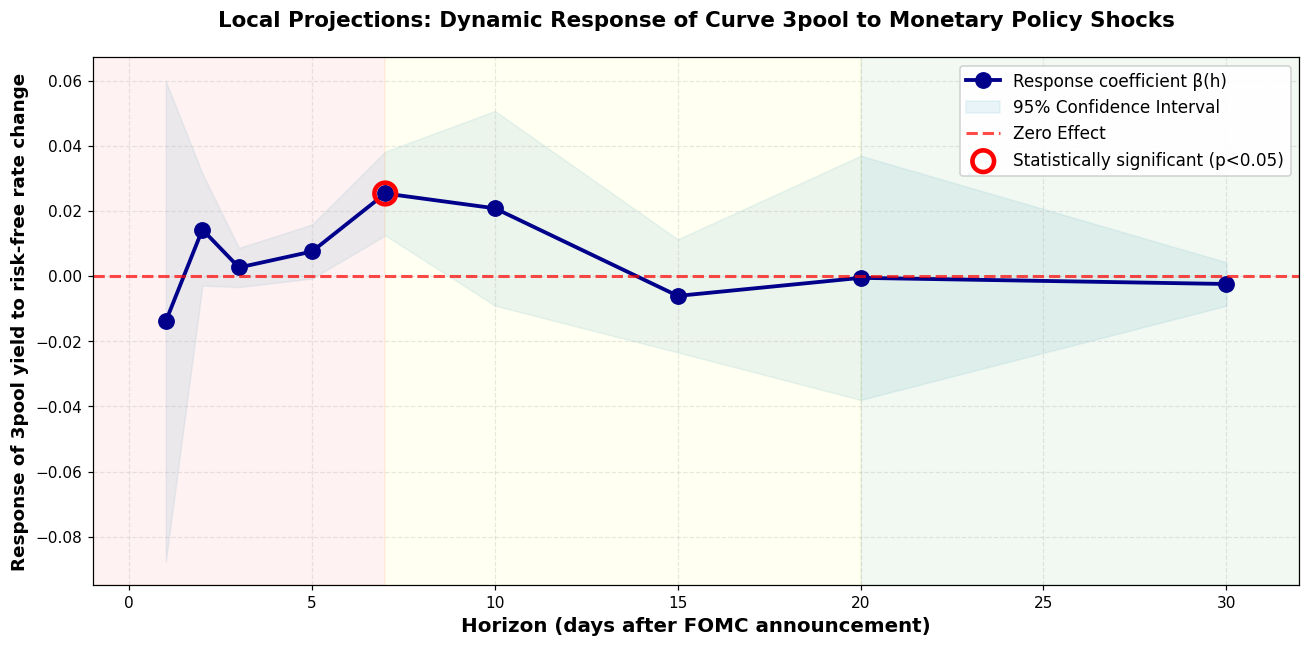

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS

# ============================================================================
# CARICA DATI
# ============================================================================
df_full = pd.read_csv(str(_DATA_DIR / 'aavenew.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
df_surprises = pd.read_csv(str(_DATA_DIR / 'ABJ-2024.csv'), parse_dates=['date'], dayfirst=True).set_index('date')

# Variabili
dependent = '3pool'
shock_var = '3m ir'
controls = ['ethperpetual', 'gas_fees', 'S&P 500', 'VIX', 'sum of tvl']

# Drop missing
df_clean = df_full[[dependent, shock_var] + controls].dropna()

# FOMC dates
fomc_dates = df_surprises.index[df_surprises.index.isin(df_clean.index)]
print(f"Number of FOMC events: {len(fomc_dates)}")
print(f"Sample period: {df_clean.index.min()} to {df_clean.index.max()}")

# ============================================================================
# LOCAL PROJECTIONS - FOMC EVENT APPROACH
# ============================================================================
horizons = [0, 1, 2, 3, 5, 7, 10, 15, 20, 30]

results_lp = []

for h in horizons:
    print(f"\nEstimating horizon h={h}...")
    
    data_for_h = []
    
    for event_date in fomc_dates:
        try:
            # Get index locations
            event_loc = df_clean.index.get_loc(event_date)
            target_loc = event_loc + h
            
            # Check bounds
            if target_loc < 0 or target_loc >= len(df_clean):
                continue
            
            target_date = df_clean.index[target_loc]
            
            # Cumulative change in 3pool yield from event to target
            y_event = df_clean.loc[event_date, dependent]
            y_target = df_clean.loc[target_date, dependent]
            cum_change_y = y_target - y_event
            
            # Cumulative change in risk-free rate from event to target
            rf_event = df_clean.loc[event_date, shock_var]
            rf_target = df_clean.loc[target_date, shock_var]
            cum_change_rf = rf_target - rf_event
            
            # Controls at event date
            controls_event = df_clean.loc[event_date, controls].values
            
            # Store
            row = [cum_change_y, cum_change_rf] + list(controls_event)
            data_for_h.append(row)
            
        except (KeyError, IndexError):
            continue
    
    if len(data_for_h) < 10:
        print(f"  ⚠️ Insufficient events for h={h}, skipping...")
        continue
    
    # Create DataFrame for this horizon
    cols = ['cum_change_y', 'cum_change_rf'] + controls
    df_h = pd.DataFrame(data_for_h, columns=cols)
    
    # Remove outliers (optional, ma consigliato per robustness)
    df_h = df_h[np.abs(df_h['cum_change_y']) < df_h['cum_change_y'].quantile(0.99)]
    
    print(f"  N events: {len(df_h)}")
    
    # Dependent: cumulative change in 3pool yield
    y = df_h['cum_change_y']
    
    # Independent: cumulative change in risk-free rate + controls
    X = df_h[['cum_change_rf'] + controls]
    X = sm.add_constant(X)
    
    # OLS with HAC
    try:
        model = OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': min(5, h+1)})
        
        beta_h = model.params['cum_change_rf']
        se_h = model.bse['cum_change_rf']
        pval_h = model.pvalues['cum_change_rf']
        ci_lower = model.conf_int().loc['cum_change_rf', 0]
        ci_upper = model.conf_int().loc['cum_change_rf', 1]
        
        results_lp.append({
            'horizon': h,
            'beta': beta_h,
            'se': se_h,
            'pval': pval_h,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper,
            'nobs': len(df_h),
            'avg_rf_change': df_h['cum_change_rf'].mean()
        })
        
        sig_star = '***' if pval_h < 0.01 else ('**' if pval_h < 0.05 else ('*' if pval_h < 0.1 else ''))
        print(f"  β({h}) = {beta_h:.6f}{sig_star}, p = {pval_h:.4f}")
        
    except Exception as e:
        print(f"  ⚠️ Error estimating model: {e}")
        continue

# Convert to DataFrame
df_lp = pd.DataFrame(results_lp)

print("\n" + "="*80)
print("LOCAL PROJECTIONS RESULTS (FOMC Events)")
print("="*80)
print(df_lp[['horizon', 'beta', 'se', 'pval', 'nobs']].to_string(index=False))

# ============================================================================
# PLOT
# ============================================================================
fig, ax = plt.subplots(figsize=(12, 6))

# Plot coefficienti
ax.plot(df_lp['horizon'], df_lp['beta'], 'o-', linewidth=2.5, markersize=10, 
        color='darkblue', label='Response coefficient β(h)')

# Confidence intervals
ax.fill_between(df_lp['horizon'], 
                df_lp['ci_lower'], 
                df_lp['ci_upper'],
                alpha=0.25, color='lightblue', label='95% Confidence Interval')

# Zero line
ax.axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Zero Effect')

# Highlight significant points
sig_df = df_lp[df_lp['pval'] < 0.05]
if len(sig_df) > 0:
    ax.scatter(sig_df['horizon'], sig_df['beta'], s=200, 
               facecolors='none', edgecolors='red', linewidth=3,
               label='Statistically significant (p<0.05)', zorder=5)

# Formatting
ax.set_xlabel('Horizon (days after FOMC announcement)', fontsize=13, fontweight='bold')
ax.set_ylabel('Response of 3pool yield to risk-free rate change', 
              fontsize=12, fontweight='bold')
ax.set_title('Local Projections: Dynamic Response of Curve 3pool to Monetary Policy Shocks',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(-1, df_lp['horizon'].max() + 2)

# Add vertical lines for interpretation zones
ax.axvspan(-1, 7, alpha=0.05, color='red', label='Short-run')
ax.axvspan(7, 20, alpha=0.05, color='yellow')
ax.axvspan(20, df_lp['horizon'].max() + 2, alpha=0.05, color='green')

plt.tight_layout()
plt.savefig('local_projections_fomc_3pool.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Plot saved: 'local_projections_fomc_3pool.png'")

# ============================================================================
# INTERPRETATION
# ============================================================================
print("\n" + "="*80)
print("INTERPRETATION")
print("="*80)

# Impact effect (h=0)
h0 = df_lp[df_lp['horizon'] == 0]
if len(h0) > 0:
    print(f"\nIMPACT EFFECT (h=0):")
    print(f"  β(0) = {h0.iloc[0]['beta']:.6f}, p = {h0.iloc[0]['pval']:.4f}")
    if h0.iloc[0]['pval'] < 0.05:
        if h0.iloc[0]['beta'] < 0:
            print("  → Significant NEGATIVE contemporaneous effect")
        else:
            print("  → Significant POSITIVE contemporaneous effect")
    else:
        print("  → NO significant contemporaneous effect")

# Short run
short_run = df_lp[df_lp['horizon'].between(1, 7)]
if len(short_run) > 0:
    avg_beta = short_run['beta'].mean()
    n_sig = (short_run['pval'] < 0.05).sum()
    
    print(f"\nSHORT RUN (1-7 days):")
    print(f"  Average β = {avg_beta:.6f}")
    print(f"  Significant: {n_sig}/{len(short_run)} horizons")
    
    if avg_beta < 0 and n_sig > 0:
        print("  → NEGATIVE short-run effect (liquidity drain)")
        print("  → Consistent with EVENT STUDY findings")
    elif avg_beta > 0:
        print("  → POSITIVE short-run effect")
    else:
        print("  → NO clear pattern")

# Long run
long_run = df_lp[df_lp['horizon'] > 15]
if len(long_run) > 0:
    avg_beta = long_run['beta'].mean()
    n_sig = (long_run['pval'] < 0.05).sum()
    
    print(f"\nLONG RUN (>15 days):")
    print(f"  Average β = {avg_beta:.6f}")
    print(f"  Significant: {n_sig}/{len(long_run)} horizons")
    
    if avg_beta > 0 and n_sig > 0:
        print("  → POSITIVE long-run effect (opportunity cost)")
        print("  → Consistent with REGRESSION findings")
    elif avg_beta < 0:
        print("  → NEGATIVE long-run effect")
    else:
        print("  → NO clear pattern")

# Summary
print("\n" + "-"*80)
print("RECONCILIATION:")
print("-"*80)

all_negative = all(df_lp['beta'] < 0)
all_positive = all(df_lp['beta'] > 0)
switches = (df_lp['beta'].iloc[0] < 0) and (df_lp['beta'].iloc[-1] > 0)

if switches:
    print("✅ Evidence of SIGN REVERSAL:")
    print("   - Short-run: Negative (event study captures this)")
    print("   - Long-run: Positive (regression captures this)")
    print("   → CONTRADDIZIONE RISOLTA!")
elif all_negative:
    print("⚠️ All horizons NEGATIVE:")
    print("   - Inconsistent with positive regression coefficient")
    print("   - Need to investigate further")
elif all_positive:
    print("⚠️ All horizons POSITIVE:")
    print("   - Inconsistent with negative event study results")
    print("   - Possible explanations:")
    print("     1. Event study may be capturing other effects")
    print("     2. Sample selection in event study")
    print("     3. Different shock identification")

print("="*80)

## With versus without controls

Original comparison calculation retained. The submitted figure is preserved separately in thesis_figures.

Source: `AAVE v2/LOCAL PROJECTIONS FINALE.ipynb`, original cell 2 (zero-based).

03_curve_local_projections.ipynb:cell5:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
03_curve_local_projections.ipynb:cell5:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
Number of FOMC events: 27
Sample period: 2021-01-01 00:00:00 to 2025-09-11 00:00:00

LOCAL PROJECTIONS WITH CONTROLS
  WITH h=1: β = -0.013858, p = 0.7124, N = 26
  WITH h=2: β = 0.014285, p = 0.1033, N = 24
  WITH h=3: β = 0.002640, p = 0.3888, N = 17
  WITH h=5: β = 0.007559*, p = 0.0742, N = 20
  WITH h=7: β = 0.025362***, p = 0.0001, N = 26
  WITH h=10: β = 0.020812, p = 0.1720, N = 23
  WITH h=15: β = -0.006079, p = 0.4921, N = 21
  WITH h=20: β = -0.000537, p = 0.9776, N = 26
  WITH h=30: β = -0.002425, p = 0.4759, N = 26

LOCAL PROJE

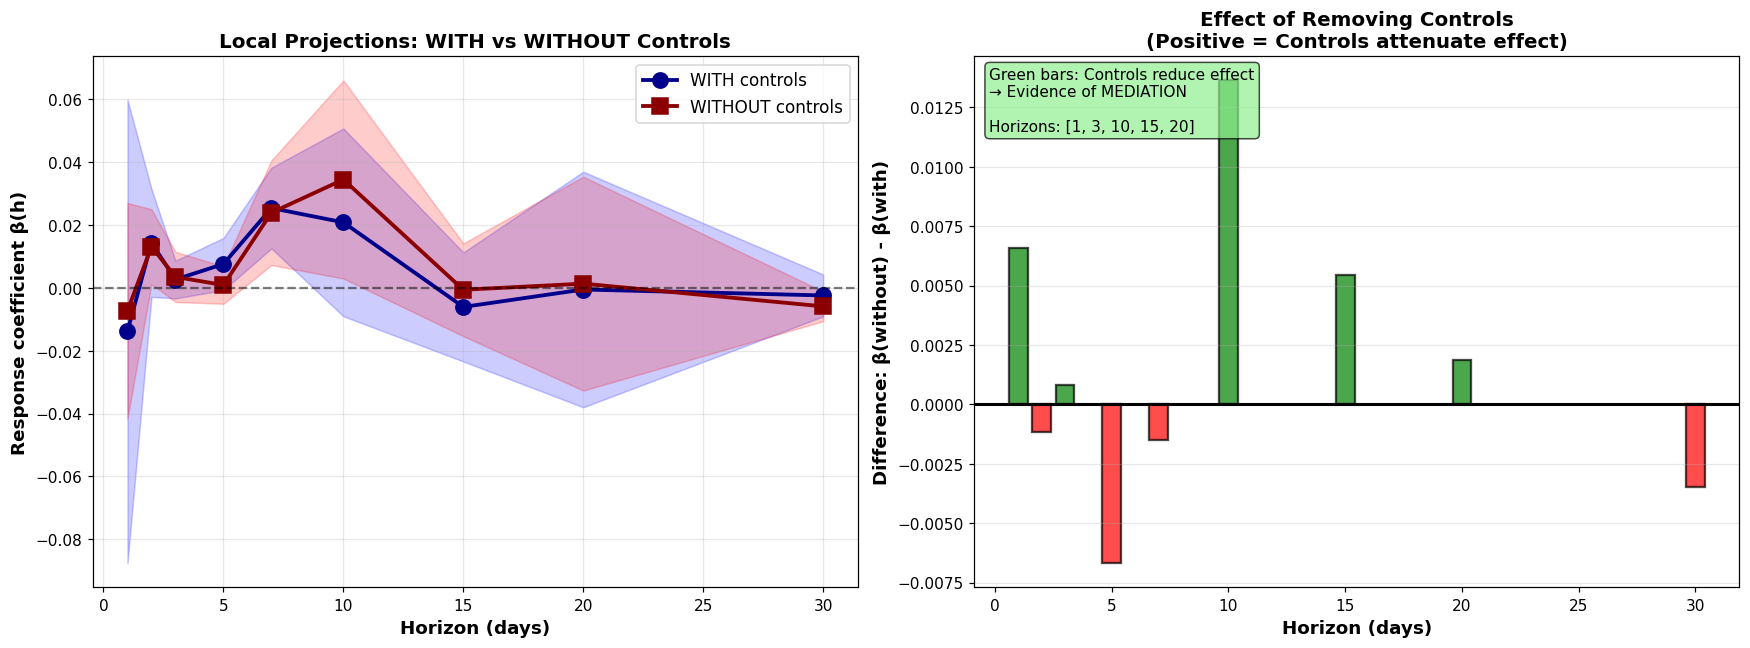

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS

# ============================================================================
# CARICA DATI
# ============================================================================
df_full = pd.read_csv(str(_DATA_DIR / 'aavenew.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
df_surprises = pd.read_csv(str(_DATA_DIR / 'ABJ-2024.csv'), parse_dates=['date'], dayfirst=True).set_index('date')

dependent = '3pool'
shock_var = '3m ir'
controls = ['ethperpetual', 'gas_fees', 'S&P 500', 'VIX', 'sum of tvl']

df_clean = df_full[[dependent, shock_var] + controls].dropna()
fomc_dates = df_surprises.index[df_surprises.index.isin(df_clean.index)]

print(f"Number of FOMC events: {len(fomc_dates)}")
print(f"Sample period: {df_clean.index.min()} to {df_clean.index.max()}")

# ============================================================================
# FUNCTION: Local Projections
# ============================================================================
def run_local_projections(df_clean, fomc_dates, dependent, shock_var, 
                          controls=None, label=""):
    """
    Run local projections with or without controls
    """
    horizons = [1, 2, 3, 5, 7, 10, 15, 20, 30]
    results_lp = []
    
    for h in horizons:
        data_for_h = []
        
        for event_date in fomc_dates:
            try:
                event_loc = df_clean.index.get_loc(event_date)
                target_loc = event_loc + h
                
                if target_loc < 0 or target_loc >= len(df_clean):
                    continue
                
                target_date = df_clean.index[target_loc]
                
                # Cumulative changes
                y_event = df_clean.loc[event_date, dependent]
                y_target = df_clean.loc[target_date, dependent]
                cum_change_y = y_target - y_event
                
                rf_event = df_clean.loc[event_date, shock_var]
                rf_target = df_clean.loc[target_date, shock_var]
                cum_change_rf = rf_target - rf_event
                
                # Build row
                row = [cum_change_y, cum_change_rf]
                
                if controls is not None:
                    controls_event = df_clean.loc[event_date, controls].values
                    row += list(controls_event)
                
                data_for_h.append(row)
                
            except (KeyError, IndexError):
                continue
        
        if len(data_for_h) < 10:
            continue
        
        # Create DataFrame
        cols = ['cum_change_y', 'cum_change_rf']
        if controls is not None:
            cols += controls
        df_h = pd.DataFrame(data_for_h, columns=cols)
        
        # Remove outliers
        df_h = df_h[np.abs(df_h['cum_change_y']) < df_h['cum_change_y'].quantile(0.99)]
        
        # Regression
        y = df_h['cum_change_y']
        
        if controls is not None:
            X = df_h[['cum_change_rf'] + controls]
        else:
            X = df_h[['cum_change_rf']]
        
        X = sm.add_constant(X)
        
        try:
            model = OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': min(5, h+1)})
            
            beta_h = model.params['cum_change_rf']
            se_h = model.bse['cum_change_rf']
            pval_h = model.pvalues['cum_change_rf']
            ci_lower = model.conf_int().loc['cum_change_rf', 0]
            ci_upper = model.conf_int().loc['cum_change_rf', 1]
            
            results_lp.append({
                'horizon': h,
                'beta': beta_h,
                'se': se_h,
                'pval': pval_h,
                'ci_lower': ci_lower,
                'ci_upper': ci_upper,
                'nobs': len(df_h)
            })
            
            sig_star = '***' if pval_h < 0.01 else ('**' if pval_h < 0.05 else ('*' if pval_h < 0.1 else ''))
            print(f"  {label} h={h}: β = {beta_h:.6f}{sig_star}, p = {pval_h:.4f}, N = {len(df_h)}")
            
        except Exception as e:
            print(f"  ⚠️ Error at h={h}: {e}")
            continue
    
    return pd.DataFrame(results_lp)

# ============================================================================
# RUN BOTH SPECIFICATIONS
# ============================================================================
print("\n" + "="*80)
print("LOCAL PROJECTIONS WITH CONTROLS")
print("="*80)
df_lp_with = run_local_projections(df_clean, fomc_dates, dependent, shock_var, 
                                    controls=controls, label="WITH")

print("\n" + "="*80)
print("LOCAL PROJECTIONS WITHOUT CONTROLS")
print("="*80)
df_lp_without = run_local_projections(df_clean, fomc_dates, dependent, shock_var, 
                                       controls=None, label="NO")

# ============================================================================
# COMPARISON TABLE
# ============================================================================
print("\n" + "="*80)
print("COMPARISON: WITH vs WITHOUT CONTROLS")
print("="*80)

comparison = pd.merge(df_lp_with[['horizon', 'beta', 'pval', 'nobs']], 
                      df_lp_without[['horizon', 'beta', 'pval']], 
                      on='horizon', 
                      suffixes=('_with', '_without'))

comparison['beta_diff'] = comparison['beta_without'] - comparison['beta_with']
comparison['pct_change'] = (comparison['beta_diff'] / comparison['beta_with'].abs()) * 100

print(comparison.to_string(index=False))

# ============================================================================
# PLOT COMPARISON
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT PANEL: Both lines
ax1 = axes[0]

# WITH controls
ax1.plot(df_lp_with['horizon'], df_lp_with['beta'], 
         'o-', linewidth=2.5, markersize=10, color='darkblue', 
         label='WITH controls')
ax1.fill_between(df_lp_with['horizon'], 
                 df_lp_with['ci_lower'], 
                 df_lp_with['ci_upper'],
                 alpha=0.2, color='blue')

# WITHOUT controls
ax1.plot(df_lp_without['horizon'], df_lp_without['beta'], 
         's-', linewidth=2.5, markersize=10, color='darkred', 
         label='WITHOUT controls')
ax1.fill_between(df_lp_without['horizon'], 
                 df_lp_without['ci_lower'], 
                 df_lp_without['ci_upper'],
                 alpha=0.2, color='red')

# Zero line
ax1.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.5)

# Formatting
ax1.set_xlabel('Horizon (days)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Response coefficient β(h)', fontsize=12, fontweight='bold')
ax1.set_title('Local Projections: WITH vs WITHOUT Controls', 
              fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=11)
ax1.grid(True, alpha=0.3)

# RIGHT PANEL: Difference
ax2 = axes[1]

diff_data = comparison[['horizon', 'beta_diff']].dropna()
ax2.bar(diff_data['horizon'], diff_data['beta_diff'], 
        color=['green' if x > 0 else 'red' for x in diff_data['beta_diff']],
        alpha=0.7, edgecolor='black', linewidth=1.5)

# Zero line
ax2.axhline(0, color='black', linestyle='-', linewidth=2)

# Formatting
ax2.set_xlabel('Horizon (days)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Difference: β(without) - β(with)', fontsize=12, fontweight='bold')
ax2.set_title('Effect of Removing Controls\n(Positive = Controls attenuate effect)', 
              fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

# Add interpretation box
mediator_horizons = diff_data[diff_data['beta_diff'] > 0]['horizon'].tolist()
if len(mediator_horizons) > 0:
    textstr = f'Green bars: Controls reduce effect\n→ Evidence of MEDIATION\n\nHorizons: {mediator_horizons}'
    props = dict(boxstyle='round', facecolor='lightgreen', alpha=0.7)
    ax2.text(0.02, 0.98, textstr, transform=ax2.transAxes, fontsize=10,
             verticalalignment='top', bbox=props)

plt.tight_layout()
plt.savefig('local_projections_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Plot saved: 'local_projections_comparison.png'")

# ============================================================================
# STATISTICAL TEST: Are differences significant?
# ============================================================================
print("\n" + "="*80)
print("STATISTICAL INTERPRETATION")
print("="*80)

# Test if differences are systematic
avg_diff = comparison['beta_diff'].mean()
n_positive = (comparison['beta_diff'] > 0).sum()
n_total = len(comparison)

print(f"\nAverage difference (β_without - β_with): {avg_diff:.6f}")
print(f"Positive differences: {n_positive}/{n_total} horizons")
print(f"Percentage: {(n_positive/n_total)*100:.1f}%")

if n_positive > n_total * 0.6:
    print("\n✅ EVIDENCE OF MEDIATION:")
    print("   Controls systematically reduce the coefficient")
    print("   → ETH_perp, gas_fees, VIX are part of the causal chain")
    print("   → Event study AR (which controls for these) captures only 'residual' effect")
elif n_positive < n_total * 0.4:
    print("\n⚠️ EVIDENCE OF CONFOUNDING:")
    print("   Controls systematically increase the coefficient")
    print("   → Controls are suppressing the true relationship")
else:
    print("\n➖ MIXED EVIDENCE:")
    print("   Controls have varying effects across horizons")

# Specific horizon analysis
print("\n" + "-"*80)
print("HORIZON-SPECIFIC ANALYSIS:")
print("-"*80)

for _, row in comparison.iterrows():
    h = int(row['horizon'])
    beta_with = row['beta_with']
    beta_without = row['beta_without']
    diff = row['beta_diff']
    
    sig_with = '***' if row['pval_with'] < 0.01 else ('**' if row['pval_with'] < 0.05 else ('*' if row['pval_with'] < 0.1 else ''))
    sig_without = '***' if row['pval_without'] < 0.01 else ('**' if row['pval_without'] < 0.05 else ('*' if row['pval_without'] < 0.1 else ''))
    
    print(f"\nh={h}:")
    print(f"  WITH controls:    β = {beta_with:+.6f}{sig_with}")
    print(f"  WITHOUT controls: β = {beta_without:+.6f}{sig_without}")
    print(f"  Difference:       Δβ = {diff:+.6f} ({row['pct_change']:+.1f}%)")
    
    if abs(diff) > 0.005:  # Substantial difference threshold
        if diff > 0:
            print(f"  → Controls REDUCE effect (mediation at h={h})")
        else:
            print(f"  → Controls INCREASE effect (suppression at h={h})")

print("\n" + "="*80)